# Análise de acessos — Sistema porta IoT

Responde, para um dia escolhido, às 6 perguntas do enunciado a partir do CSV exportado pelo backend.

**Premissas**
- Timestamps do CSV estão em UTC; convertidos para `America/Sao_Paulo` antes de filtrar o dia.
- Permanência: soma de cada `entrada` até a `saida` seguinte do colaborador. Entrada sem saída não entra na soma e é avisada. Saída sem entrada é ignorada.
- "Pessoas" = colaboradores distintos (`colaborador_id`).

In [1]:
import pandas as pd

CSV = "eventos-exemplo.csv"   # CSV exportado pelo backend
DIA = "2026-10-28"            # dia analisado (fuso America/Sao_Paulo)
COLABORADOR = "pereira"       # nome do colaborador (pergunta 3)

In [2]:
df = pd.read_csv(CSV)
df["timestamp"] = pd.to_datetime(df["timestamp"], utc=True).dt.tz_convert("America/Sao_Paulo")
dia = df[df["timestamp"].dt.strftime("%Y-%m-%d") == DIA].sort_values("timestamp")
print(f"{len(dia)} eventos em {DIA}")

5 eventos em 2026-10-28


## 1. Quantas pessoas entraram?

In [3]:
dia[dia["tipo"] == "entrada"]["colaborador_id"].nunique()

1

## 2. Quantas pessoas saíram?

In [4]:
dia[dia["tipo"] == "saida"]["colaborador_id"].nunique()

1

## 3. Tempo de permanência do colaborador

In [5]:
p = dia[(dia["nome"] == COLABORADOR) & dia["tipo"].isin(["entrada", "saida"])]
total, aberta = pd.Timedelta(0), None
for _, r in p.iterrows():
    if r["tipo"] == "entrada":
        aberta = r["timestamp"]
    elif aberta is not None:
        total += r["timestamp"] - aberta
        aberta = None
print(f"{COLABORADOR}: {total}")
if aberta is not None:
    print(f"Atenção: entrada sem saída às {aberta:%H:%M:%S} (não somada)")

pereira: 0 days 00:00:55


## 4. Quantos acessos negados?

In [6]:
int((dia["tipo"] == "acesso_negado").sum())

0

## 5. Quantas tentativas de invasão?

In [7]:
int((dia["tipo"] == "tentativa_invasao").sum())

3

## 6. Quem mais tentou acessar sem autorização?

Acessos negados e tentativas de invasão, agrupados por tag.

In [8]:
tent = dia[dia["tipo"].isin(["acesso_negado", "tentativa_invasao"])]
tent.groupby("tag_rfid").size().sort_values(ascending=False).rename("tentativas")

tag_rfid
770978550471    2
771439528262    1
Name: tentativas, dtype: int64

## Acessos por tipo no dia

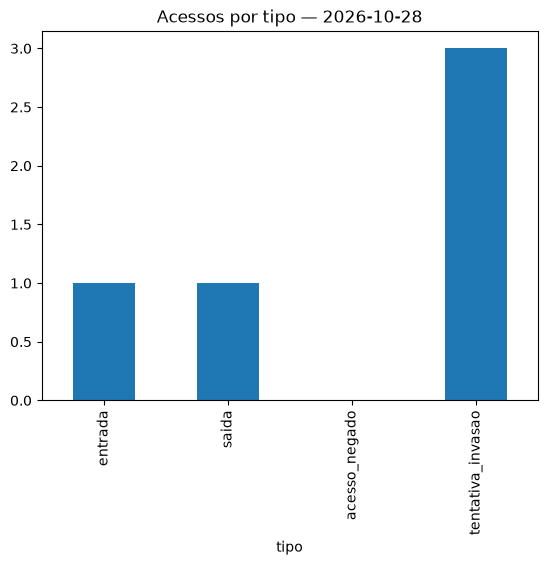

In [9]:
TIPOS = ["entrada", "saida", "acesso_negado", "tentativa_invasao"]
dia["tipo"].value_counts().reindex(TIPOS, fill_value=0).plot.bar(title=f"Acessos por tipo — {DIA}");